<a href="https://colab.research.google.com/github/makaog5-sudo/CRM-SP500/blob/main/CRM_stock_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 1 : DATA PREPARATION

In [17]:
!pip install yfinance pandas numpy


In [18]:
import pandas as pd, numpy as np, yfinance as yf, sklearn, scipy
from datetime import datetime, timezone


print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__,
      "| sklearn", sklearn.__version__, "| scipy", scipy.__version__)

# --- Task 1.1: Extract S&P 500 tickers from Wikipedia ---
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

tables = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500 = next(
    table for table in tables
    if "Symbol" in table.columns and "Security" in table.columns
)

retrieval_date = datetime.now(timezone.utc).strftime("%Y-%m-%d")

sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

# Save the list with its retrieval date
sp500["Retrieval_Date_UTC"] = retrieval_date
sp500.to_csv("sp500_tickers.csv", index=False)

tickers = sp500["Yahoo_Ticker"].tolist()

print("Retrieval date:", retrieval_date)
print("Total tickers:", len(tickers))
print("First 10 tickers:", tickers[:10])

sp500[["Symbol", "Yahoo_Ticker", "Security", "GICS Sector"]].head()

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66 | sklearn 1.6.1 | scipy 1.16.3
Retrieval date: 2026-11-23
Total tickers: 503
First 10 tickers: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


,Symbol,Yahoo_Ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [19]:

# Download all S&P 500 stocks and the benchmark
all_tickers = tickers + ["^GSPC"]

stock_data = yf.download(
    all_tickers,
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False,
    group_by="column",
    threads=True,
    progress=True
)

print("Dataset shape:", stock_data.shape)
print("Number of trading days:", len(stock_data))

stock_data.head()


[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'HONA', 'VYLR', 'Q', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Dataset shape: (1005, 3024)
Number of trading days: 1005


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009125  125.537125  84.219131  139.149994  97.269699   
2021-01-05  114.941261  127.089211  85.089996  148.300003  98.473198   
2021-01-06  118.093239  122.811203  84.354958  142.770004  98.268158   
2021-01-07  121.235588  127.001907  85.257782  151.270004  99.222038   
2021-01-08  122.100456  128.098099  85.705215  149.770004  99.498413   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029343  485.339996  132.622620  42.189484  ...   
2021-01-05  33.319485  233.350281  485.690002  134.993179  43.010090  ...   
2021-01-06  34.783871  235.901611  466.309998  135.601700  44.752827  ...   
2021-01-07  34.460564  238.127319  477.739990  141.332733  44.355232  ...   
2021-01-08  34.650742  238.995804  485.100006  142.359085  44.473656  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 3024 columns]

In [20]:
raw = stock_data
stock_data.to_pickle("raw_prices_2021_2024.pkl.gz")

print("Stock data saved successfully!")


Stock data saved successfully!


In [21]:
%cd /content

/content


In [22]:
# --- Task 1.2: Data validation and exclusion log ---
raw = stock_data
adj, close, vol = raw["Adj Close"], raw["Close"], raw["Volume"]
bench_dates = adj["^GSPC"].dropna().index
print("Duplicate dates:", raw.index.duplicated().sum())

exclusions = []
for t in tickers:
    if t not in adj.columns or adj[t].isna().all():
        exclusions.append((t, "No Yahoo data for 2021-2024 (failed download)")); continue
    a, c, v = adj[t].reindex(bench_dates), close[t].reindex(bench_dates), vol[t].reindex(bench_dates)
    if a.first_valid_index() > bench_dates[0]:
        exclusions.append((t, f"Incomplete history: first price {a.first_valid_index().date()}"))
    elif a.isna().any() or c.isna().any() or v.isna().any():
        exclusions.append((t, f"Missing values inside period ({int(a.isna().sum())} days)"))
    elif (a <= 0).any() or (c <= 0).any():
        exclusions.append((t, "Non-positive price"))
    elif (v <= 0).any():
        exclusions.append((t, f"Zero volume on {int((v <= 0).sum())} days"))

excl_log = pd.DataFrame(exclusions, columns=["Ticker", "Reason"])
included = [t for t in tickers if t not in set(excl_log["Ticker"])]
excl_log.to_csv("exclusion_log.csv", index=False)
print(f"Included: {len(included)} | Excluded: {len(excl_log)}")

moves = close[included].pct_change(fill_method=None).abs()
print("Possible corporate-action days (|Close move| > 40%):\n", moves[moves > 0.4].stack())
excl_log

Duplicate dates: 0
Included: 486 | Excluded: 17
Possible corporate-action days (|Close move| > 40%):
 Date        Ticker
2022-08-05  CVNA      0.400716
2022-12-07  CVNA      0.429210
2023-01-12  CVNA      0.460000
2023-06-08  CVNA      0.560206
2023-07-19  CVNA      0.402010
2024-04-11  GL        0.531402
2024-07-26  DXCM      0.406583
2024-11-15  BE        0.591867
dtype: float64


,Ticker,Reason
0,APP,Incomplete history: first price 2021-04-15
1,COIN,Incomplete history: first price 2021-04-14
2,CEG,Incomplete history: first price 2022-01-19
3,EXE,Incomplete history: first price 2021-02-10
4,FDXF,No Yahoo data for 2021-2024 (failed download)
5,FERG,Zero volume on 27 days
6,GEHC,Incomplete history: first price 2022-12-15
7,GEV,Incomplete history: first price 2024-03-27
8,HONA,No Yahoo data for 2021-2024 (failed download)
9,Q,No Yahoo data for 2021-2024 (failed download)


In [23]:
# TASK 1.3: MEAN WEEKLY RETURN AND BETA

import pandas as pd
import numpy as np


valid_tickers = list(included)

adj_prices = stock_data["Adj Close"]

# Keep validated stocks and S&P 500 benchmark
selected = valid_tickers + ["^GSPC"]
adj_prices = adj_prices[selected]

weekly_prices = adj_prices.resample("W-FRI").last()

weekly_prices = weekly_prices.loc[
    "2021-01-08":"2024-12-27"
]

# Calculate returns without filling missing values
weekly_returns = weekly_prices.pct_change(fill_method=None)

market_returns = weekly_returns["^GSPC"]

results = []

for ticker in valid_tickers:

    paired = pd.concat(
        [weekly_returns[ticker], market_returns],
        axis=1
    ).dropna()

    paired.columns = ["Stock", "Market"]

    # Arithmetic mean weekly return
    mean_return = paired["Stock"].mean()

    # Weekly beta
    beta = (
        paired["Stock"].cov(paired["Market"])
        / paired["Market"].var()
    )

    results.append({
        "Ticker": ticker,
        "Mean_Weekly_Return": mean_return,
        "Weekly_Beta": beta,
        "Aligned_Weeks": len(paired)
    })

features = pd.DataFrame(results)

print("Stocks analysed:", len(features))
print("Minimum aligned weeks:", features["Aligned_Weeks"].min())
print("Maximum aligned weeks:", features["Aligned_Weeks"].max())

display(features.head())


features.to_csv("weekly_return_beta.csv", index=False)

Stocks analysed: 486
Minimum aligned weeks: 207
Maximum aligned weeks: 207


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
0,MMM,0.001142,0.869079,207
1,AOS,0.001991,1.042804,207
2,ABT,0.000971,0.583544,207
3,ABBV,0.003749,0.425366,207
4,ACN,0.002376,1.143300,207


In [24]:
features[["Mean_Weekly_Return", "Weekly_Beta"]].describe().round(4)

,Mean_Weekly_Return,Weekly_Beta
count,486.0000,486.0000
mean,0.0029,0.9737
std,0.0027,0.4073
min,-0.0045,0.0555
25%,0.0012,0.6666
50%,0.0026,0.9506
75%,0.0042,1.1795
max,0.0178,3.7786


In [25]:
# TASK 1.4: ADAPTED RFM — based on lecture script RFM_Yahoofin.ipynb (cell 0)
import pandas as pd
import numpy as np

shares = list(included)                     # CHANGED: 486 validated shares, not 10
observation_date = stock_data.index.max()   # CHANGED: fixed observation date

results = []

for ticker in shares:
    # CHANGED: use saved snapshot instead of yf.Ticker(ticker).history(period="1y")
    data = pd.DataFrame({
        "Close": stock_data["Close"][ticker],
        "Volume": stock_data["Volume"][ticker],
    }).loc[:observation_date].sort_index()

    average_volume = data["Volume"].shift(1).rolling(20).mean()
    data["HighVolume"] = data["Volume"] > 2 * average_volume

    valid = data.loc[average_volume.notna()].copy()
    if len(valid) < 60:
        print(f"{ticker}: insufficient history")
        continue

    recent = valid.tail(60)
    high_volume_days = valid.loc[valid["HighVolume"]]


    recency = (
        (valid.index[-1].date() - high_volume_days.index[-1].date()).days
        if not high_volume_days.empty else None
    )

    results.append({
        "Ticker": ticker,
        "Recency": recency,
        "Frequency": int(recent["HighVolume"].sum()),
        "Monetary": (recent["Close"] * recent["Volume"]).sum(),
    })

rfm = pd.DataFrame(results).set_index("Ticker")
rfm["Recency"] = rfm["Recency"].astype("Float64")

print("Observation date:", observation_date.date())
print("Shares with RFM:", len(rfm), "| Missing Recency:", rfm["Recency"].isna().sum())

# join with return/beta features + one feature table
if "Ticker" in features.columns:
    features = features.set_index("Ticker")
features = features.drop(columns=["Recency", "Frequency", "Monetary", "GICS Sector"], errors="ignore")
features = features.join(rfm).join(sp500.set_index("Yahoo_Ticker")["GICS Sector"])
features.to_csv("feature_table.csv")

features[["Recency", "Frequency", "Monetary"]].describe().round(2)

Observation date: 2024-12-31
Shares with RFM: 486 | Missing Recency: 0


,Recency,Frequency,Monetary
count,486.0,486.00,4.860000e+02
mean,20.41,2.99,3.940419e+10
std,21.34,1.33,1.291388e+11
min,4.0,0.00,1.297483e+09
25%,11.0,2.00,1.019517e+10
50%,11.0,3.00,1.668382e+10
75%,14.75,4.00,3.227689e+10
max,222.0,8.00,1.847697e+12


In [26]:
# TASK 1.5: Worked example, validation checks and feature summary

t = "AAPL"
ex = pd.DataFrame({"Close": stock_data["Close"][t], "Volume": stock_data["Volume"][t]})
ex["Prev20_Avg"] = ex["Volume"].shift(1).rolling(20).mean()   # excludes current day
ex["Threshold"] = 2 * ex["Prev20_Avg"]
ex["HighVolume"] = ex["Volume"] > ex["Threshold"]
ex["Close_x_Volume"] = ex["Close"] * ex["Volume"]
last60 = ex.tail(60)

print(f"WORKED EXAMPLE: {t} (observation date {observation_date.date()})")
print("Latest event date:", ex.index[ex["HighVolume"]].max().date())
print("Recency  =", features.loc[t, "Recency"], "calendar days")
print("Frequency =", int(last60["HighVolume"].sum()), "event days in last 60 sessions")
print(f"Monetary = ${last60['Close_x_Volume'].sum():,.0f}")
print("\nEvent days in last 60 sessions:")
display(last60[last60["HighVolume"]].round(0))

print("\nCHECKS")
print("Baseline available for all last-60 days:", last60["Prev20_Avg"].notna().all())
print("Same-day events (Recency = 0):", (features["Recency"] == 0).sum())
print("No-event shares (Recency missing):", features["Recency"].isna().sum())
print("Common share set size:", len(features))

print("\nFEATURE SUMMARY")
display(features[["Mean_Weekly_Return", "Weekly_Beta", "Recency", "Frequency", "Monetary"]].describe().round(4))

WORKED EXAMPLE: AAPL (observation date 2024-12-31)
Latest event date: 2024-12-20
Recency  = 11.0 calendar days
Frequency = 2 event days in last 60 sessions
Monetary = $623,303,377,707

Event days in last 60 sessions:


,Close,Volume,Prev20_Avg,Threshold,HighVolume,Close_x_Volume
Date,,,,,,
2024-11-25,233.0,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.0,147495300,45004605.0,90009210.0,True,3.753608e+10



CHECKS
Baseline available for all last-60 days: True
Same-day events (Recency = 0): 0
No-event shares (Recency missing): 0
Common share set size: 486

FEATURE SUMMARY


,Mean_Weekly_Return,Weekly_Beta,Recency,Frequency,Monetary
count,486.0000,486.0000,486.0,486.0000,4.860000e+02
mean,0.0029,0.9737,20.4074,2.9897,3.940419e+10
std,0.0027,0.4073,21.3424,1.3308,1.291388e+11
min,-0.0045,0.0555,4.0,0.0000,1.297483e+09
25%,0.0012,0.6666,11.0,2.0000,1.019517e+10
50%,0.0026,0.9506,11.0,3.0000,1.668382e+10
75%,0.0042,1.1795,14.75,4.0000,3.227689e+10
max,0.0178,3.7786,222.0,8.0000,1.847697e+12


TASK 2: STOCK SEGMENTATION AND SENSITIVITY ANALYSIS

Common share set: 486

Skewness (before transform):
Mean_Weekly_Return     0.87
Weekly_Beta            1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: float64


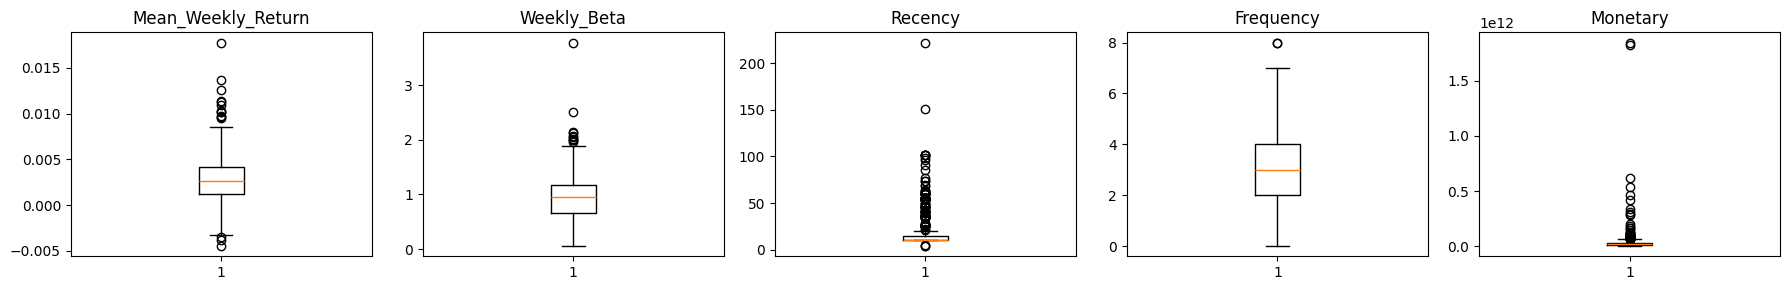


Skewness of log1p(Monetary): 1.08
Matrices ready: (486, 2) (486, 3)


In [27]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


rr_cols  = ["Mean_Weekly_Return", "Weekly_Beta"]
rfm_cols = ["Recency", "Frequency", "Monetary"]
data = features.dropna(subset=rr_cols + rfm_cols).copy()
print("Common share set:", len(data))


print("\nSkewness (before transform):")
print(data[rr_cols + rfm_cols].astype(float).skew().round(2))

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col in zip(axes, rr_cols + rfm_cols):
    ax.boxplot(data[col].astype(float)); ax.set_title(col)
plt.tight_layout(); plt.savefig("feature_boxplots.png", dpi=150); plt.show()

# Reduce the influence of very large traded values (as in lecture)
X_rr  = data[rr_cols].astype(float).copy()
X_rfm = data[rfm_cols].astype(float).copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
print("\nSkewness of log1p(Monetary):", round(X_rfm["Monetary"].skew(), 2))

# Standardise each matrix separately
X_rr_scaled  = StandardScaler().fit_transform(X_rr)
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)
print("Matrices ready:", X_rr_scaled.shape, X_rfm_scaled.shape)


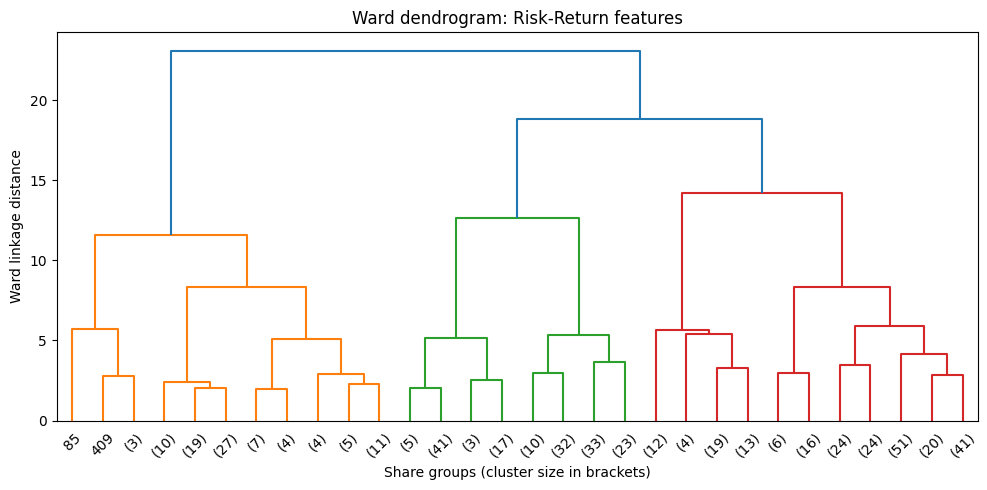


WARD — Risk-Return


,k,Silhouette,Cluster sizes
0,2,0.339,"[394, 92]"
1,3,0.274,"[230, 164, 92]"
2,4,0.282,"[182, 164, 48, 92]"
3,5,0.304,"[182, 66, 98, 48, 92]"
4,6,0.320,"[182, 66, 98, 48, 87, 5]"
5,7,0.324,"[160, 66, 98, 48, 22, 87, 5]"
6,8,0.321,"[160, 66, 98, 48, 22, 56, 31, 5]"


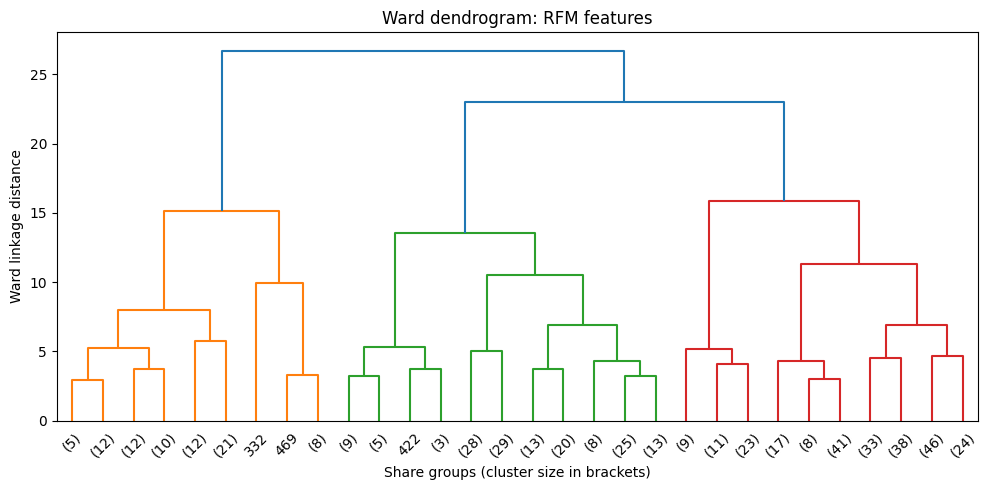


WARD — RFM


,k,Silhouette,Cluster sizes
0,2,0.368,"[404, 82]"
1,3,0.304,"[154, 250, 82]"
2,4,0.289,"[154, 207, 82, 43]"
3,5,0.305,"[154, 207, 72, 43, 10]"
4,6,0.314,"[136, 207, 18, 72, 43, 10]"
5,7,0.292,"[136, 66, 18, 72, 141, 43, 10]"
6,8,0.302,"[57, 66, 79, 18, 72, 141, 43, 10]"


In [28]:
# TASK 2.2: AGGLOMERATIVE (WARD) CLUSTERING
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

matrices = {"Risk-Return": X_rr_scaled, "RFM": X_rfm_scaled}
ward_results = {}

for name, X_scaled in matrices.items():
    hierarchy = linkage(X_scaled, method="ward")
    ward_results[name] = hierarchy


    plt.figure(figsize=(10, 5))
    dendrogram(hierarchy, truncate_mode="lastp", p=30, leaf_rotation=45)
    plt.title(f"Ward dendrogram: {name} features")
    plt.xlabel("Share groups (cluster size in brackets)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout(); plt.savefig(f"dendrogram_{name}.png", dpi=150); plt.show()

    rows = []
    for k in range(2, 9):
        labels = cut_tree(hierarchy, n_clusters=k).ravel() + 1
        sizes = pd.Series(labels).value_counts().sort_index().tolist()
        rows.append({"k": k, "Silhouette": round(silhouette_score(X_scaled, labels), 3),
                     "Cluster sizes": sizes})
    print(f"\nWARD — {name}")
    display(pd.DataFrame(rows))


K-MEANS — Risk-Return


,k,Silhouette,Inertia,Cluster sizes
0,2,0.387,621.6,"[343, 143]"
1,3,0.329,461.2,"[202, 165, 119]"
2,4,0.327,371.6,"[160, 154, 132, 40]"
3,5,0.341,309.6,"[166, 131, 112, 50, 27]"
4,6,0.334,265.4,"[158, 113, 111, 56, 43, 5]"
5,7,0.331,227.5,"[143, 85, 83, 74, 48, 48, 5]"
6,8,0.354,194.4,"[136, 79, 78, 76, 43, 40, 29, 5]"



K-MEANS — RFM


,k,Silhouette,Inertia,Cluster sizes
0,2,0.423,1066.8,"[418, 68]"
1,3,0.325,796.6,"[270, 152, 64]"
2,4,0.341,609.8,"[212, 122, 91, 61]"
3,5,0.358,514.7,"[198, 122, 87, 68, 11]"
4,6,0.346,437.4,"[141, 120, 104, 69, 41, 11]"
5,7,0.347,386.3,"[141, 120, 104, 68, 41, 11, 1]"
6,8,0.350,342.2,"[140, 106, 83, 66, 64, 15, 11, 1]"


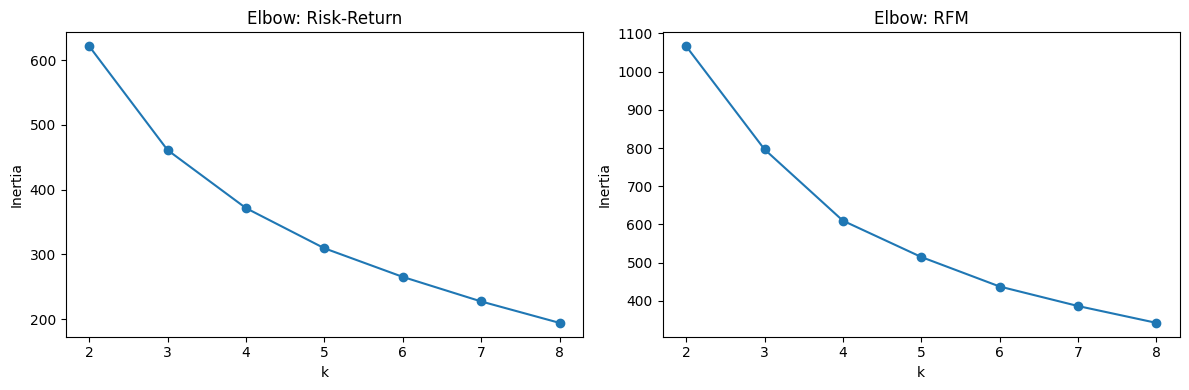

In [29]:
# TASK 2.3: K-MEANS — method from RFM_KMeans lecture
from sklearn.cluster import KMeans

kmeans_tables = {}
for name, X_scaled in matrices.items():
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=20, random_state=42)   # seed + multiple initialisations
        labels = km.fit_predict(X_scaled)
        rows.append({"k": k, "Silhouette": round(silhouette_score(X_scaled, labels), 3),
                     "Inertia": round(km.inertia_, 1),
                     "Cluster sizes": sorted(pd.Series(labels).value_counts().tolist(), reverse=True)})
    kmeans_tables[name] = pd.DataFrame(rows)
    print(f"\nK-MEANS — {name}")
    display(kmeans_tables[name])

# Elbow plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, tbl) in zip(axes, kmeans_tables.items()):
    ax.plot(tbl["k"], tbl["Inertia"], marker="o"); ax.set_title(f"Elbow: {name}")
    ax.set_xlabel("k"); ax.set_ylabel("Inertia")
plt.tight_layout(); plt.savefig("kmeans_elbow.png", dpi=150); plt.show()

Shares: 486

===== Risk-Return (k = 2) =====
Adjusted Rand Index (Ward vs K-means): 0.598

Ward cluster averages in original units:


,Mean_Weekly_Return,Weekly_Beta,Shares
Ward_Risk-Return,,,
1,0.0020,0.8979,394
2,0.0063,1.2981,92



KMeans cluster averages in original units:


,Mean_Weekly_Return,Weekly_Beta,Shares
KMeans_Risk-Return,,,
1,0.0053,1.3505,143
2,0.0018,0.8166,343


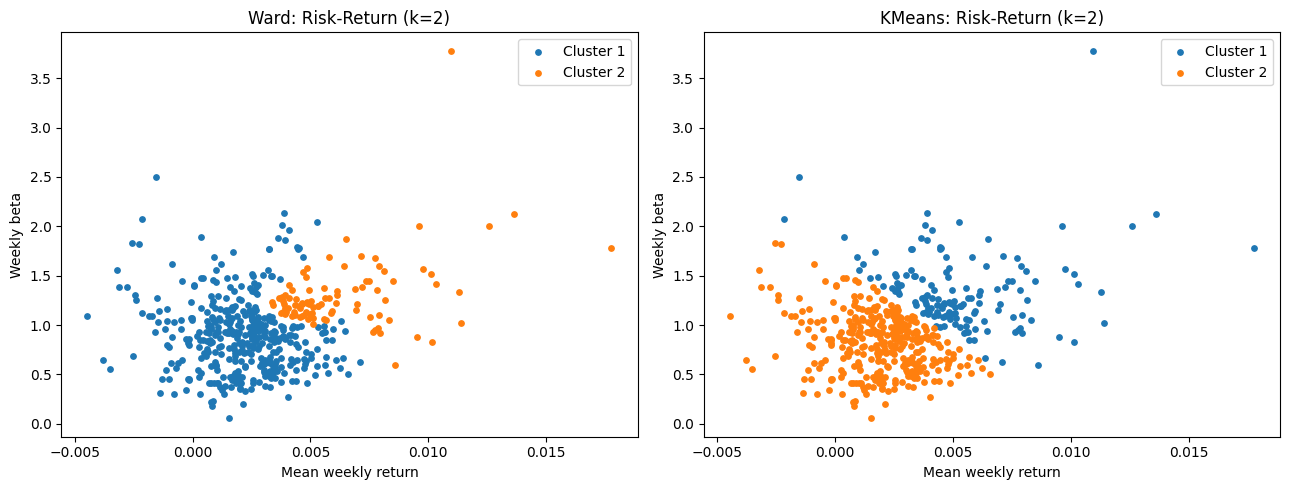


===== RFM (k = 2) =====
Adjusted Rand Index (Ward vs K-means): 0.7

Ward cluster averages in original units:


,Recency,Frequency,Monetary,Shares
Ward_RFM,,,,
1,12.7153,3.1708,3.783020e+10,404
2,58.3049,2.0976,4.715898e+10,82



KMeans cluster averages in original units:


,Recency,Frequency,Monetary,Shares
KMeans_RFM,,,,
1,13.4234,3.1866,3.269100e+10,418
2,63.3382,1.7794,8.067057e+10,68


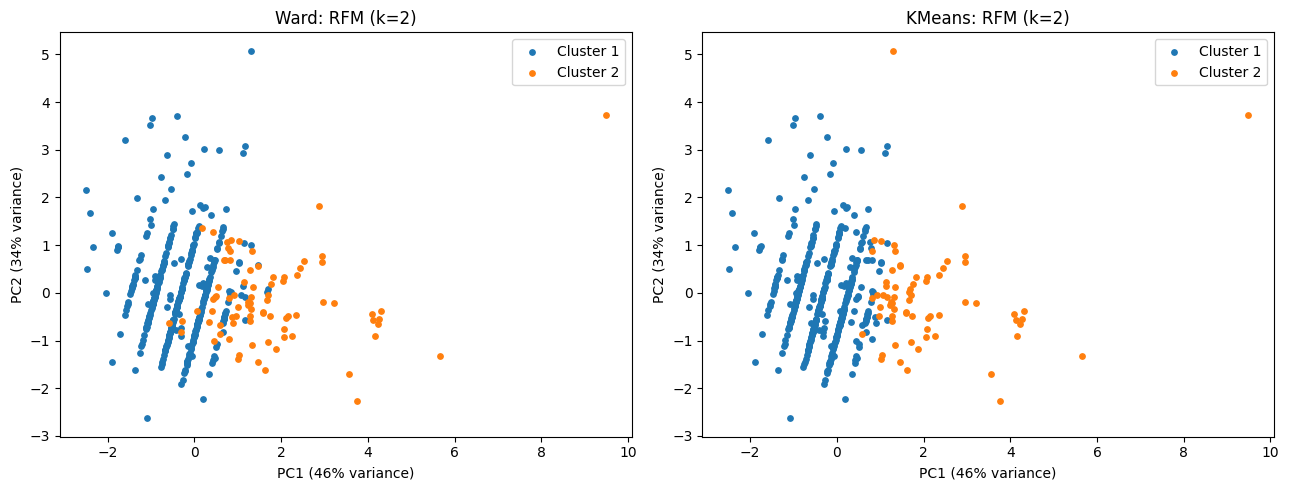

Saved feature_table_with_clusters.csv


In [33]:
# TASK 2.4: FINAL SOLUTIONS, PROFILES (ORIGINAL UNITS), 2D PLOTS, ALGORITHM COMPARISON
# Profiles + scatter adapted from RFM_Yahoofin.ipynb (cells 3 & 5)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree

# Rebuild feature matrices (same as 2.1)
if "Ticker" in features.columns:
    features = features.set_index("Ticker")
rr_cols  = ["Mean_Weekly_Return", "Weekly_Beta"]
rfm_cols = ["Recency", "Frequency", "Monetary"]
data = features.dropna(subset=rr_cols + rfm_cols).copy()
X_rr  = data[rr_cols].astype(float)
X_rfm = data[rfm_cols].astype(float).copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
matrices = {"Risk-Return": StandardScaler().fit_transform(X_rr),
            "RFM":         StandardScaler().fit_transform(X_rfm)}
ward_results = {n: linkage(X, method="ward") for n, X in matrices.items()}
print("Shares:", len(data))

K = {"Risk-Return": 2, "RFM": 2}
cols = {"Risk-Return": rr_cols, "RFM": rfm_cols}

for name, X_scaled in matrices.items():
    k = K[name]
    data[f"Ward_{name}"] = cut_tree(ward_results[name], n_clusters=k).ravel() + 1
    data[f"KMeans_{name}"] = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X_scaled) + 1

    print(f"\n===== {name} (k = {k}) =====")
    print("Adjusted Rand Index (Ward vs K-means):",
          round(adjusted_rand_score(data[f"Ward_{name}"], data[f"KMeans_{name}"]), 3))
    for algo in ["Ward", "KMeans"]:
        lab = f"{algo}_{name}"
        prof = data.groupby(lab)[cols[name]].mean()
        prof["Shares"] = data[lab].value_counts().sort_index()
        print(f"\n{algo} cluster averages in original units:")
        display(prof.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    if name == "RFM":
        pca = PCA(n_components=2, random_state=42)
        pts = pca.fit_transform(X_scaled)
        xlab = f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)"
        ylab = f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)"
    else:
        pts = data[rr_cols].values
        xlab, ylab = "Mean weekly return", "Weekly beta"
    for ax, algo in zip(axes, ["Ward", "KMeans"]):
        for c, grp in data.groupby(f"{algo}_{name}"):
            idx = data.index.get_indexer(grp.index)
            ax.scatter(pts[idx, 0], pts[idx, 1], label=f"Cluster {c}", s=15)
        ax.set_title(f"{algo}: {name} (k={k})"); ax.set_xlabel(xlab); ax.set_ylabel(ylab); ax.legend()
    plt.tight_layout(); plt.savefig(f"clusters_{name}.png", dpi=150); plt.show()

data.to_csv("feature_table_with_clusters.csv")
print("Saved feature_table_with_clusters.csv")

In [32]:
# TASK 2.5: RFM SENSITIVITY — correlations adapted from RFM_Yahoofin.ipynb (cell 6)

# 2.5.1 Correlations among R, F and log1p(M)
corr_data = data[["Recency", "Frequency"]].astype(float).copy()
corr_data["LogMonetary"] = np.log1p(data["Monetary"].astype(float))
print("Correlations among the clustering inputs:")
display(corr_data.corr().round(2))

# 2.5.2 Remove Monetary: Ward on R and F only, same shares, same k, standardised afresh
k_rfm = K["RFM"]
X_rf_scaled = StandardScaler().fit_transform(data[["Recency", "Frequency"]].astype(float))
data["Ward_RF_only"] = cut_tree(linkage(X_rf_scaled, method="ward"), n_clusters=k_rfm).ravel() + 1

ari = adjusted_rand_score(data["Ward_RFM"], data["Ward_RF_only"])
print(f"\nAdjusted Rand Index (Ward RFM vs Ward R+F only, k={k_rfm}):", round(ari, 3))

# Compare traded value (liquidity proxy) profiles
for lab in ["Ward_RFM", "Ward_RF_only"]:
    prof = data.groupby(lab).agg(Shares=("Monetary", "size"),
                                 Recency=("Recency", "mean"),
                                 Frequency=("Frequency", "mean"),
                                 Median_Monetary=("Monetary", "median"),
                                 Mean_Monetary=("Monetary", "mean"))
    print(f"\n{lab} profiles:")
    display(prof.round(2))

display(pd.crosstab(data["Ward_RFM"], data["Ward_RF_only"]))
data.to_csv("feature_table_with_clusters.csv")

Correlations among the clustering inputs:


,Recency,Frequency,LogMonetary
Recency,1.00,-0.35,0.15
Frequency,-0.35,1.00,0.01
LogMonetary,0.15,0.01,1.00



Adjusted Rand Index (Ward RFM vs Ward R+F only, k=2): 0.873

Ward_RFM profiles:


,Shares,Recency,Frequency,Median_Monetary,Mean_Monetary
Ward_RFM,,,,,
1,404,12.72,3.17,1.604728e+10,3.783020e+10
2,82,58.3,2.10,1.784903e+10,4.715898e+10



Ward_RF_only profiles:


,Shares,Recency,Frequency,Median_Monetary,Mean_Monetary
Ward_RF_only,,,,,
1,397,12.3,3.21,1.546400e+10,3.780680e+10
2,89,56.56,2.01,2.084781e+10,4.652963e+10


Ward_RF_only,1,2
Ward_RFM,,
1,394,10
2,3,79
